# Does a half-known word map learned on 24 keys carry to 8 unseen keys, and does VPD agree?

*E58, 2026-10-30. Record and full tables: `reports/analyses/2026-10-30_analysis_e58-open-pair.md`. Plan:
`reports/plans/2026-10-30_plan_e58-open-pair.md`. Words as in `GOALS.md` → Terms.*

## The answer

No carry-over on the half-known map, and the decomposition reads the opposite; but the measure itself then failed its
positive control. At the unseen keys the half-known map's update pushed the 24 trained answers up and the model's own
other preferences down: a lookup, not a sharpening. Two maps the model can already apply at any key did carry further,
and the decomposition read them as old subcomponents too (a limit: a new circuit of old pieces reads that way as well).
Yet the copy map crossed the held-out test's bar on only one seed of three. So a filed prediction failed, and the test
is not used against the decomposition.

In [1]:
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP = ROOT / "experiments" / "open_pair"
RUN = json.loads((EXP / "results" / "run.json").read_text())
ST, SC = RUN["states"], RUN["score"]
A1 = json.loads((EXP / "results" / "amend1.json").read_text())
# figures: experiments/open_pair/plot.py, from run.json and amend1.json only
print("stage-0 controls passed:", RUN["stage0"]["pass"], "| elicit labels:", SC["P0"]["labels"],
      "| cipher labels:", SC["P1"]["labels"])
print("Amendment 1 verdict:", A1["score"]["verdict"], "| copy labels:", A1["score"]["C2"]["labels"],
      "| rank-1 labels:", A1["score"]["C1"]["labels"])

stage-0 controls passed: True | elicit labels: ['new', 'new', 'new'] | cipher labels: ['new', 'new', 'new']
Amendment 1 verdict: none | copy labels: ['neither', 'reuses', 'neither'] | rank-1 labels: ['neither', 'neither', 'neither']


## What we were trying to test

The re-gating line asks whether a VPD decomposition can tell a fine-tune that strengthens something the model already
does from one that teaches something new. Its numbers have only been scored against labels fixed by how each task was
built. Here the label comes from behaviour alone.

**The task.** Each window is Pile text, then a rare marker token, then a key word; the model must predict the key's
value next. Two maps share the 32 keys and the windows. In the *elicit map*, each value is a word the original model W₀
already ranks 2nd to 20th after that key, such as " formed" → " from". In the *cipher*, the values are arbitrary words
W₀ almost never gives there. The cipher's unseen values cannot be guessed from its trained ones, so it is the label's
negative control.

**What changed.** E54's fine-tune recipe ran on only 24 of the 32 keys, three seeds per map. The other 8 keys never sat
at a training window's key position. The elicit map is read at step 10, when the trained keys are learned. The cipher is
read at the step whose total weight change matches the elicit state's.

**The label.** For a window, the *specific gain* is the fine-tune's rise in the log-odds of the window's own value, minus
the mean rise of the map's other 31 values. Subtracting them removes a shift shared by the whole value set. A first,
stopped job found such a shift on E54's cipher. The trained-key gain $G_\text{spec}$ is the mean specific gain on
unused windows of the trained keys. The held-out gain $H_\text{spec}$ is the same on the 8 held-out keys, and
$x = H_\text{spec} / G_\text{spec}$. At 0 the unseen keys gained
nothing; at 1 they gained as much as the trained ones. The label is "reuses" if $x \ge 0.5$ and "new" if $x$ is at or below
three bootstrap standard deviations $s$.

**The readings**, E54's, on the least-squares split of each weight change:

- $r$, the share of the fine-tune's gain recovered when the subcomponents stay at W₀'s and only Γ's CI values change. It
  reads 1 if switching existing subcomponents on carries all the gain.
- The *stand-in ratio*, the CI-masked model's gain over the gain of the split subcomponents with every mask open. It is
  roughly the gain from Γ's new CI values over the subcomponent gain, not "the share Γ keeps", and has no ceiling at 1.
- $S$, steering's share: one mean vector added at one block. It never reads the decomposition.

Each reading says "reuses" at 0.5 or more.

## What we expected, and why

We left the elicit label open, at about even odds for "reuses": if the fine-tune sharpened what W₀ already prefers after
each key, unseen keys would gain too. Every cipher had to read "new". We expected r and the stand-in ratio to stay high
on the elicit map, as in E54, so the prediction that they agree with the label would pass exactly when the label read
"reuses". We also expected both readings to separate the elicit map from the cipher again.

## Did the fine-tune carry over to the keys it never saw?

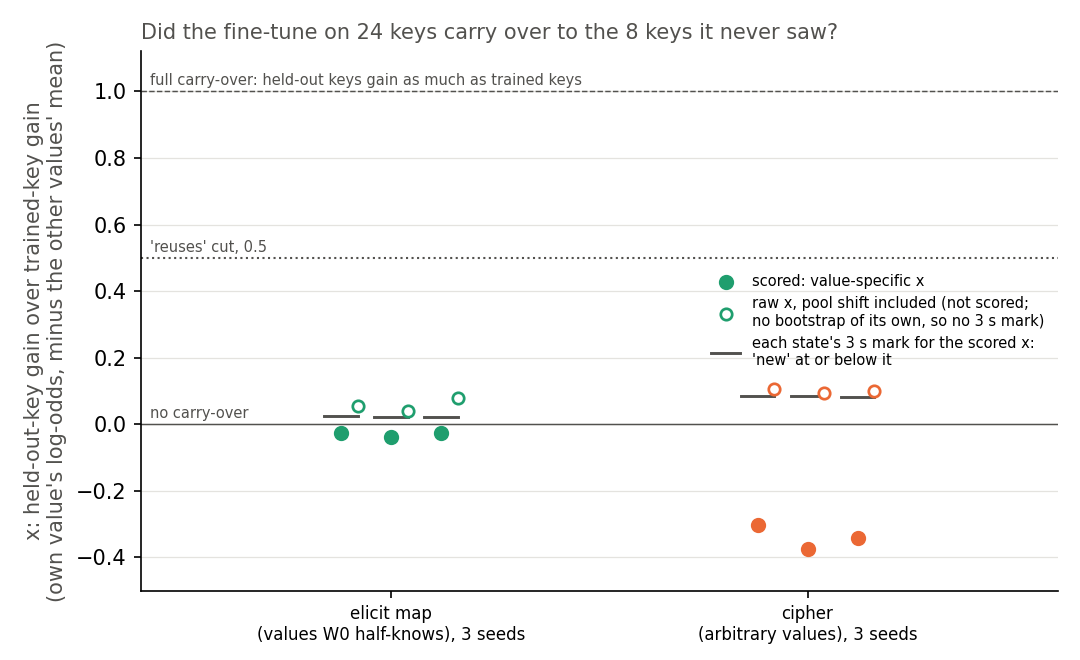

In [2]:
display(Image(filename=str(EXP / "figures" / "label.png")))

In [3]:
rows = ["| state | trained-key gain | held-out gain | x | label |", "|---|---|---|---|---|"]
for t in ("elicit", "cipher"):
    for s in (0, 1, 2):
        d = ST[f"{t}_s{s}"]
        rows.append(f"| {t}, seed {s} | {d['G_spec']:.2f} | {d['H_spec']:.2f} | {d['x']:.3f} | {d['label']} |")
display(Markdown("\n".join(rows)))

| state | trained-key gain | held-out gain | x | label |
|---|---|---|---|---|
| elicit, seed 0 | 18.18 | -0.50 | -0.027 | new |
| elicit, seed 1 | 18.43 | -0.70 | -0.038 | new |
| elicit, seed 2 | 18.51 | -0.48 | -0.026 | new |
| cipher, seed 0 | 10.67 | -3.24 | -0.303 | new |
| cipher, seed 1 | 9.39 | -3.54 | -0.377 | new |
| cipher, seed 2 | 9.94 | -3.40 | -0.342 | new |

**Reading it.** No. On all three elicit seeds the held-out keys' specific gain was slightly negative, so $x$ sits just
below 0 and the label is "new". The trained keys gained about 18 log-odds on the same measure. The cipher reads "new"
too, further below 0, so the negative control passed. The hollow points keep the shared shift in and read 0.04 to 0.08
for the elicit map, far from the cut; they have no bootstrap of their own, so no label. Resampling the 8 keys instead of windows changes no label.

## Was carry-over possible, or did the task rule it out?

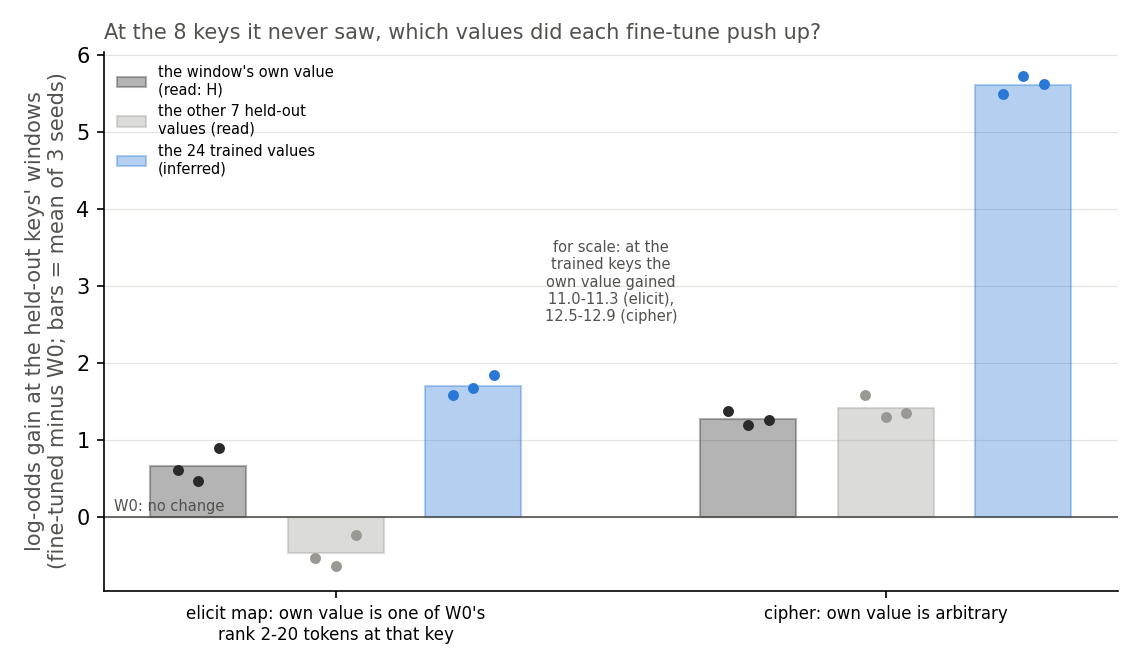

In [4]:
display(Image(filename=str(EXP / "figures" / "heldout_gain.png")))

**Reading it.** Carry-over was possible, and the fine-tune took that route only weakly. There is no rule from key to
value here, so the one way unseen keys could gain is a general sharpening of what W₀ already prefers after each key.
That would raise the held-out key's own value most. The own value rose by about 0.6 log-odds, while the 24 trained values
rose by about 1.7. Here the trained values' rise is inferred from three read means, since the 32 values
are distinct; Amendment 1 later read it directly and it agrees to within 5e-8 on all six states.

That push hides a small key-specific boost. Against its 7 held-out siblings, the own value gained about 1.1 more on the
elicit map, and about 0.1 to 0.2 less on the cipher. Each contrast comes from two read means. The boost is about 6% of the
trained keys' specific gain. So the update is mostly 24 lookups plus a push toward the trained values, with a small
key-specific boost. Amendment 1, below, reads the trained values' push directly; the label stands as filed.

In [5]:
rows = ["| state | own value | 7 held-out siblings | own minus siblings |", "|---|---|---|---|"]
for t in ("elicit", "cipher"):
    for s in (0, 1, 2):
        d = ST[f"{t}_s{s}"]
        rows.append(f"| {t}, seed {s} | {d['H']:+.2f} | {d['H_other']:+.2f} | {d['H'] - d['H_other']:+.3f} |")
display(Markdown("\n".join(rows)))

| state | own value | 7 held-out siblings | own minus siblings |
|---|---|---|---|
| elicit, seed 0 | +0.61 | -0.53 | +1.145 |
| elicit, seed 1 | +0.46 | -0.64 | +1.098 |
| elicit, seed 2 | +0.90 | -0.23 | +1.127 |
| cipher, seed 0 | +1.38 | +1.58 | -0.208 |
| cipher, seed 1 | +1.19 | +1.29 | -0.105 |
| cipher, seed 2 | +1.26 | +1.35 | -0.095 |

*Gains at the held-out keys' windows, log-odds, fine-tuned minus W₀.*

## Do the decomposition's readings agree with the label?

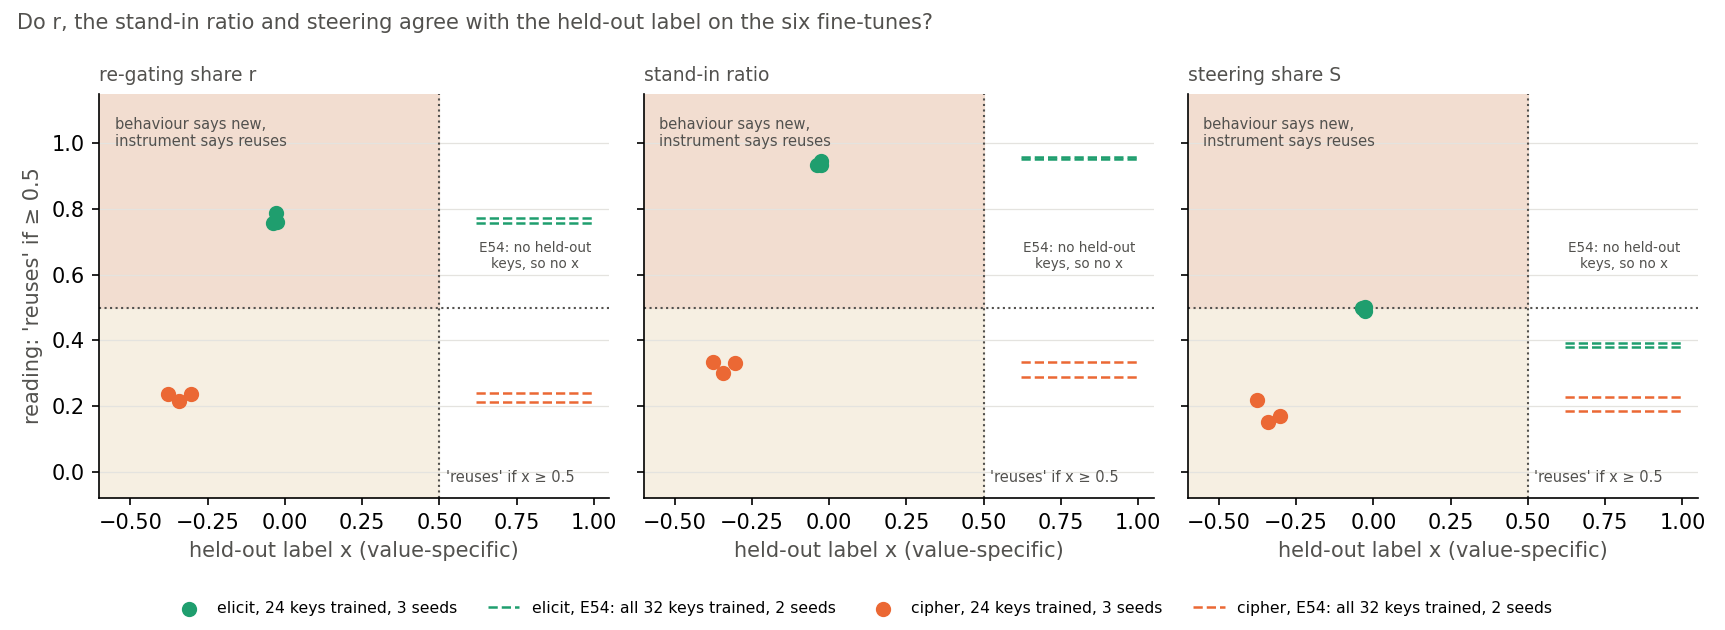

In [6]:
display(Image(filename=str(EXP / "figures" / "agreement.png")))

In [7]:
rows = ["| state | r | stand-in ratio | steering S | label |", "|---|---|---|---|---|"]
for t in ("elicit", "cipher"):
    for s in (0, 1, 2):
        d = ST[f"{t}_s{s}"]
        rows.append(f"| {t}, seed {s} | {d['r']:.3f} | {d['ratio']:.3f} | {d['S']:.3f} | {d['label']} |")
display(Markdown("\n".join(rows)))

| state | r | stand-in ratio | steering S | label |
|---|---|---|---|---|
| elicit, seed 0 | 0.787 | 0.946 | 0.501 | new |
| elicit, seed 1 | 0.757 | 0.934 | 0.498 | new |
| elicit, seed 2 | 0.758 | 0.934 | 0.490 | new |
| cipher, seed 0 | 0.236 | 0.330 | 0.171 | new |
| cipher, seed 1 | 0.238 | 0.336 | 0.220 | new |
| cipher, seed 2 | 0.217 | 0.302 | 0.152 | new |

**Reading it.** No: r and the stand-in ratio read "reuses" on every elicit state, while the label reads "new". The
green points sit in the upper-left box of the first two panels, level with E54's values for the same map with all keys
trained. Both readings still separate the elicit map from the cipher: r by 0.54 and the ratio by 0.62. Seed ranges are near 0.03.

Steering agrees with the label on more states, but that is not a finding. Its three elicit values are 0.50, 0.50 and
0.49, on its own cut, so it scores by sitting on the line. We keep it out of the headline.

## Amendment 1: two checks on how to read this

E58 left two doubts. Was "new" guaranteed by the task, or did the update really ignore what W₀ already prefers at unseen
keys? And can the label read "reuses" at all, when no state on this model ever had? A second job checked both at no cost.

**The readout.** On E58's six saved states, at the held-out keys' windows, we read three log-odds gains. They are the
gain of the window's own value, the gain $T$ of the trained keys' values, and the gain $R_\text{peer}$ of the other
words among W₀'s top 20 at that key. A lookup
pushes $T$ above $R_\text{peer}$. A sharpening of W₀ pushes $R_\text{peer}$ above 0. All three read 0 at W₀.

**The positive control.** Two new maps on the same windows, keys and 24/8 split, E54's recipe, three seeds. In the
*rank-1 map* each key's value is W₀'s own top next word after it, so "say what you would have said" holds at every key.
In the *copy map* each key's value is the key itself, one rule for every key. Both should carry to unseen keys and read
"reuses" under E58's unchanged label.

**What we expected.** A lookup on all three elicit states, at about 85%. The copy map reading "reuses" on two of three
seeds, at about 75%. The rank-1 map testable at about even odds, since it needs 3 held-out keys whose value no trained
key shares.

### At the unseen keys, did the update push the trained answers or W₀'s own preferences?

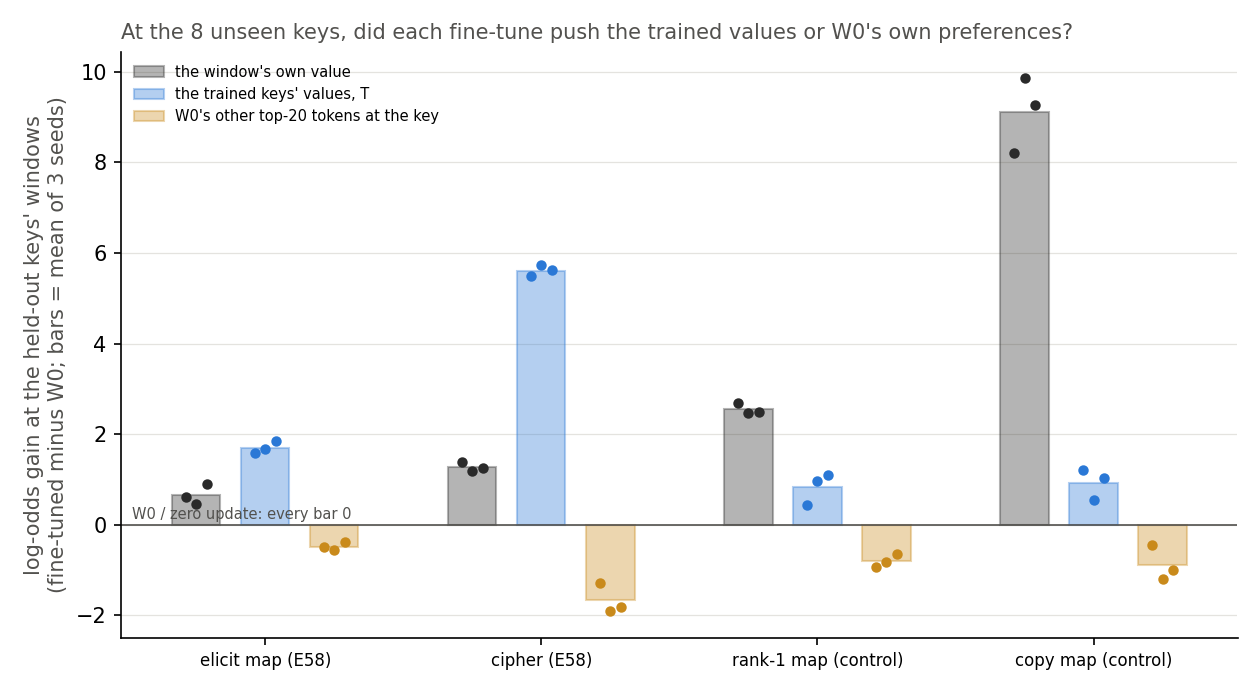

In [8]:
display(Image(filename=str(EXP / "figures" / "a1_readout.png")))

**Reading it.** The trained answers: on every elicit seed the update is a lookup, as filed. The 24 trained values rose
by 1.6 to 1.8 log-odds at unseen keys, while W₀'s other top-20 words there fell by 0.4 to 0.6. W₀'s first choice fell
too, so no sharpening hides at rank 1. The cipher reads the same, more strongly. One caveat: this verdict leaves the
own value out, so the copy map also reads "lookup", although its own value rose by 8 to 10 at unseen keys. It says what
else the update pushed, not whether it carried.

### Can the label read "reuses", and do the readings follow the carry?

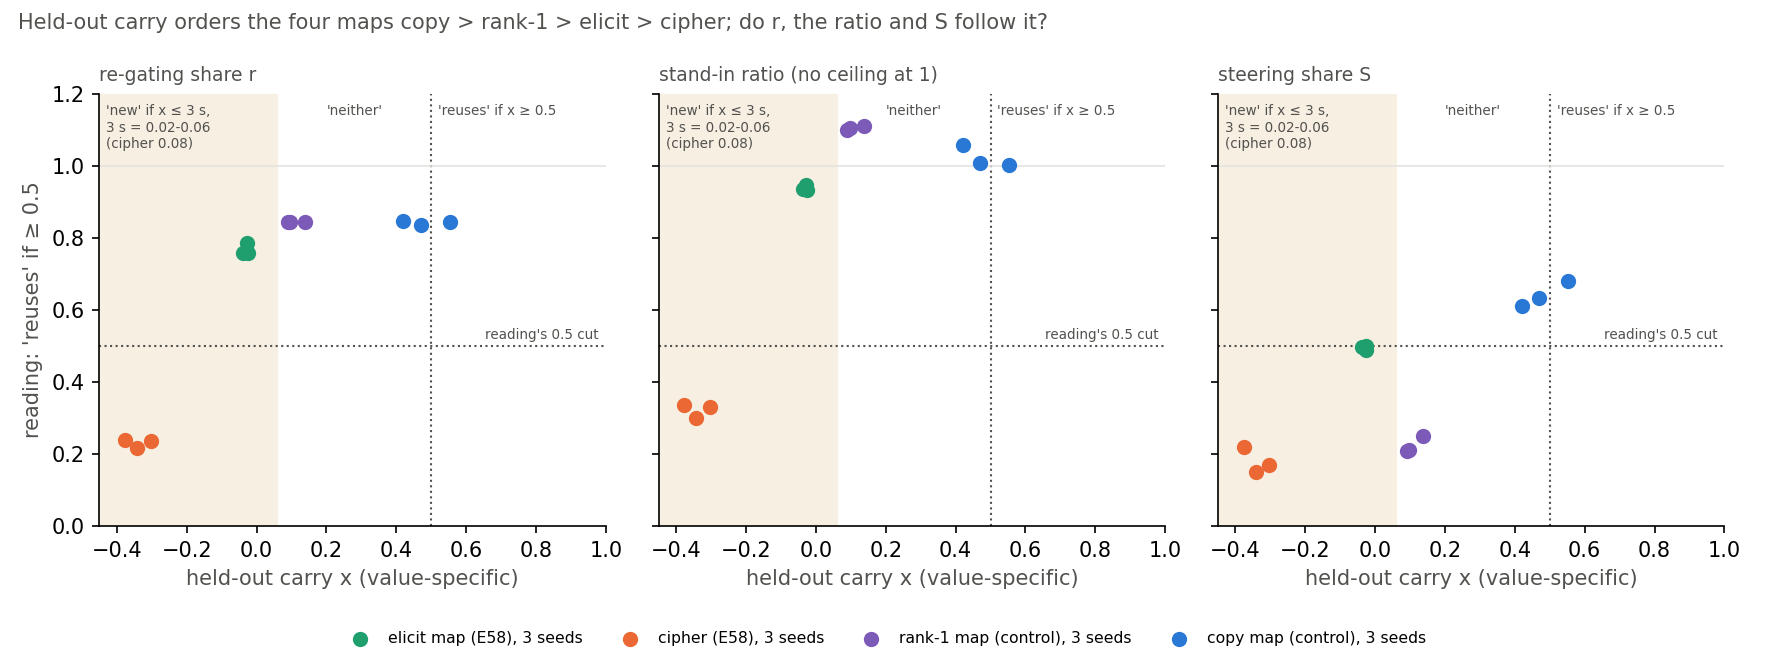

In [9]:
display(Image(filename=str(EXP / "figures" / "a1_carry.png")))

In [10]:
C = A1["control"]
rows = ["| state | held-out carry x | label | r | stand-in ratio |", "|---|---|---|---|---|"]
for m in ("rank1", "copy"):
    for s in (0, 1, 2):
        d = C[f"{m}_s{s}"]
        rows.append(f"| {m}, seed {s} | {d['x']:.3f} | {d['label']} | {d['r']:.3f} | {d['ratio']:.3f} |")
display(Markdown("\n".join(rows)))

| state | held-out carry x | label | r | stand-in ratio |
|---|---|---|---|---|
| rank1, seed 0 | 0.138 | neither | 0.845 | 1.110 |
| rank1, seed 1 | 0.097 | neither | 0.843 | 1.105 |
| rank1, seed 2 | 0.090 | neither | 0.843 | 1.099 |
| copy, seed 0 | 0.420 | neither | 0.846 | 1.057 |
| copy, seed 1 | 0.553 | reuses | 0.843 | 1.003 |
| copy, seed 2 | 0.470 | neither | 0.834 | 1.007 |

**Reading it.** Not at the filed bar: the positive control failed. Read the horizontal axis first. The copy map carried
most, 0.42 to 0.55 of the trained gain, and reads "reuses" on one seed of three. We predicted two of three at about 75%,
so that prediction fails. The rank-1 map carried 0.09 to 0.14 and could not be scored. Only one of its held-out keys has
a value of its own, so its carry can ride on the push toward trained values. In raw log-odds the copy map's unseen keys
gained 0.63 to 0.75 of the trained keys' gain. The value-specific measure is lower because, at trained keys only, the
map's other values fell by over 4 log-odds, which enlarges the denominator.

Now the vertical axes. The re-gating share r stays level across copy, rank-1 and elicit, at 0.76 to 0.85, while carry
runs from half to none. The stand-in ratio is flat the same way, and both separate only the cipher. Steering puts the
rank-1 map beside the cipher. The stand-in ratio exceeds 1 on both controls, and that is allowed: it is not a share. It
is close to the gain from Γ's new CI values alone over the gain of the split subcomponents with every mask open. Nothing
caps the first by the second.

## What we learned

This is the lead's reading, not a proof: no check here separates it from "the decomposition is wrong".

VPD's unit is the rank-one subcomponent, so a new lookup built from old subcomponents, switched on in a new pattern,
reads "elicited" to r and the stand-in ratio. Here the elicit values are words W₀ already says after these keys, so the
subcomponents that write them exist; the cipher's do not, and its readings are low. The held-out label asks a
different question: does a rule carry to unseen inputs? On a lookup over existing words those two answers can differ,
and they do here, on three seeds each way. Every claim holds only at the level of VPD's subcomponents.

Amendment 1 confirms the lookup: the update pushed the trained answers, not W₀'s own preferences. It also removes the
label's standing. A rule the model applies at any key carried about half its trained gain at best, so the 0.5 bar may be
beyond reach of the recipe, or the value-specific denominator (inflated by the other values' drop at trained keys) may
fall short; the evidence fits either. E58's failed agreement test therefore counts neither for nor against VPD.
And r and the stand-in ratio stay level while carry runs from none to half, so whatever they read, it is not held-out
carry. Ask #14 to the user, whether "reuses" means "built from existing subcomponents" or "generalises to unseen
inputs", stays open.

## How compelling is the evidence

Three fine-tune seeds per map, one key split, one decomposition. The label's real unit is the 8 held-out keys, and it
holds when keys are resampled. The label is blind to a carry-over that raises every value alike. Its positive control
failed: the copy map read "reuses" on one seed of three, and the rank-1 map was not testable on this split. A code
reviewer noted that the rank-1 values were picked on windows that include the scoring windows, which biases its carry
slightly toward "new" (reasoned, not measured). The readings reproduced E54 to four decimals before any fine-tune.

## Surprises

- **A filed prediction failed against a confident lean.** We put the copy map reading "reuses" on two of three seeds at
  about 75%; it did on one. It was filed as always testable, so it is a fail.
- The rank-1 map had a single held-out key with a value of its own; the stand-in ratio read above 1 on both controls.
- A filed prediction failed: the decomposition's labels disagree with the behavioural label on every elicit state. It
  was filed at about even odds, so this is a failure as filed, not a reversal of a confident lean.
- Steering's share on the elicit map rose to about 0.5 with 24 keys, from about 0.39 with all 32. We assert no cause.
- At unseen keys the cipher pushes its trained values up by about 5.6 log-odds, three times the elicit map's push.

## What next

With no working positive control, the held-out label is not used against r or the stand-in ratio. The lead is
consulting Fable on what follows.

## Scorecard

| id | claim | read | verdict |
|---|---|---|---|
| P0 | the elicit label, a lean toward "reuses" | new ×3 | new; lean missed |
| P1 | every cipher reads "new" | new ×3 | pass |
| P2 | r's and the ratio's labels equal the behavioural label | reuses ×3 vs new ×3 | **fail**, both |
| P3 | the decomposition agrees with the label more often than steering | r 3, ratio 3, S 5 of 6 | "steering_better" as scored; not a finding, S on its cut |
| P4 | r and the ratio separate elicit from cipher, as E54 | gaps 0.54, 0.62; ranges 0.03 | pass, both |
| A1 | at unseen keys every elicit update is a lookup | gap 2.1-2.2 vs 3 sd 0.23 | pass |
| C1 | the rank-1 map reads "reuses" on 2 of 3 seeds | 1 novel key of 3 needed; neither ×3 | not testable |
| C2 | the copy map reads "reuses" on 2 of 3 seeds | neither, reuses, neither | **fail** |
| verdict | the label has a positive control | C1 not testable, C2 fail | none |
| C3 | r and the ratio agree with each earned label | copy seed 1 only | pass, both, n = 1 |

## Departures from the literature

- The bar is the reuse line's Stage B rule, from Jain et al.'s Definition 2 with the user's bounded g. Stage B reads the
  share an interchange patch carries; here it is read on behaviour only, with no patch.
- The gain is value-specific, the map's other values' mean gain subtracted, filed before any fine-tune.
- The bootstrap resamples windows, which share keys, where Stage B resamples independent texts; a key-level bootstrap is
  reported and changes no label.
- The 0.5 cut on the stand-in ratio copies E12's rule for r; the ratio has no ceiling at 1, so the cut is a convention.
- The gate on the trained-key gain was lowered from 8 to 5.148 before any fine-tune, keeping Fable's fraction of E54's
  gain; every elicit state cleared it by more than three times.
- Amendment 1: the rank-1 values are W₀'s top token over E54's training windows of each key. Those include the scoring
  windows, an in-sample choice for W₀ only.
- Amendment 1: ranks are over the full vocabulary, not word-like tokens only. The gate is E58's, not set from W₀'s
  rank-1 probability. The copy map always ran, and a 3-key guard was added to the rank-1 map.

## Not run

A rank-1 map on a split with 3 or more held-out keys of its own, or with values picked apart from the scoring windows.
The control maps at later steps or under another recipe. The novelty column on Γ's CI patterns. The interchange patch.
More key splits, seeds or decomposition seeds; the cipher at its own step; Qwen.

## Provenance

Job 46266, MATS `debug`, one L40, $0, about 3 minutes; code `b11a921`, results commit `16f43d6`. Stopped stage-0 job
46259, results commit `080b1f2`. Amendment 1: job 46332, MATS `debug`, one L40, $0, about 3 minutes; code `0714b79`,
results commit `c1b4ef9`. Weight changes and logs in `~/commute-data/results-large/open_pair/`.